In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "masbudget").is_dir() else Path.cwd().parent
os.chdir(ROOT)
sys.path[:0] = [str(ROOT), str(ROOT / "experiments")]
import pandas as pd
from IPython.display import Image, display
from lib import load, md_table
import plots
plots.style()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 4)
%matplotlib inline

# E7 + E8 - Information and learning

Notes in `experiments/E07_*.md`, `E08_*.md`.

In [2]:
s = load('e07_summary')
(s[s.tau == 0.2].pivot(index='policy', columns='condition', values='q_real')).round(3)

condition,blind,difficulty,difficulty (noise 0.1),difficulty (noise 0.25),difficulty (noise 0.5),oracle
policy,,,,,,
Best model,0.199,0.296,0.295,0.295,0.297,0.837
Best model + reserve,0.702,0.715,0.713,0.710,0.706,0.837
Cascade (verified),0.770,0.782,0.783,0.782,0.782,0.831
Cheapest model,0.676,0.676,0.676,0.676,0.676,0.676
MCKP (optimal),0.697,0.726,0.719,0.718,0.708,0.837
Pacing + reserve (ours),0.696,0.721,0.718,0.713,0.705,0.837
Pacing + reserve + abstain (ours),0.696,0.721,0.718,0.713,0.705,0.837


Realized pass@1 at tau = 0.2. Per-task (oracle) knowledge is worth ~11 points; coordination with difficulty-level knowledge is worth less than that. Within every information regime the pacing mechanism stays within 1% of that regime's MCKP:

In [3]:
(100 * s.pivot_table(index='policy', columns='condition', values='gap_exp', aggfunc='max')).round(2)

condition,blind,difficulty,difficulty (noise 0.1),difficulty (noise 0.25),difficulty (noise 0.5),oracle
policy,,,,,,
Best model,87.47,85.69,85.68,85.71,85.77,36.87
Best model + reserve,0.64,6.00,6.05,5.97,5.73,1.32
Cascade (verified),11.27,4.63,5.75,7.27,9.78,8.77
Cheapest model,16.67,16.44,16.69,16.72,16.31,19.19
MCKP (optimal),0.00,0.00,0.00,0.00,0.00,0.00
Pacing + reserve (ours),0.05,0.24,0.24,0.24,0.23,1.00
Pacing + reserve + abstain (ours),0.05,0.24,0.24,0.24,0.23,0.29


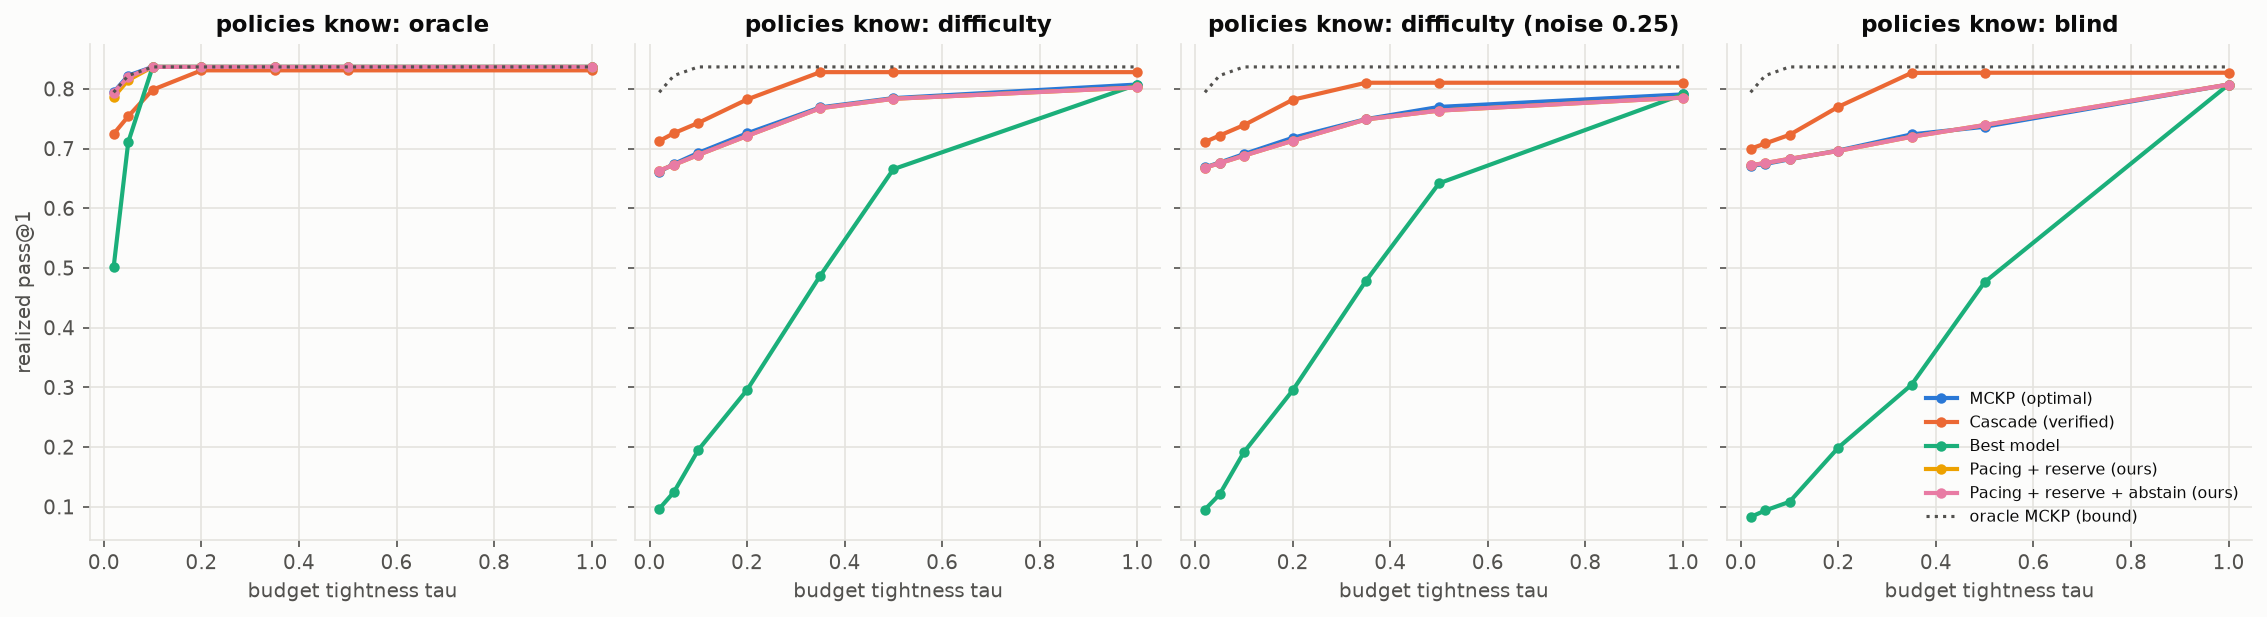

In [4]:
display(Image('experiments/figures/e07_information.png'))

## E8 - Learning agents (qualities unknown, learned online from call outcomes)

In [5]:
l = load('e08_summary')
l[l.tau == 0.2][['J', 'policy', 'q_exp', 'q_real', 'gap_exp', 'regret_successes']]

,J,policy,q_exp,q_real,gap_exp,regret_successes
9,200,Cheapest model,0.6663,0.6760,0.0976,14.3030
10,200,MCKP (optimal),0.7383,0.7255,0.0000,-0.1026
11,200,"Pacing + reserve (knows q-hat, no price history)",0.7383,0.7228,0.0000,-0.1026
12,200,"Pacing + reserve (ours, knows q-hat)",0.7378,0.7211,0.0007,0.0000
13,200,UCB + pacing + reserve (c=0),0.7207,0.7314,0.0239,3.4298
14,200,UCB + pacing + reserve (c=0.25),0.7179,0.7217,0.0276,3.9775
15,200,"UCB + pacing + reserve (c=0.25, blind prior)",0.7083,0.7103,0.0408,5.9168
16,200,UCB + pacing + reserve (c=0.5),0.7033,0.7098,0.0475,6.9045
17,200,UCB + pacing + reserve (c=1),0.6911,0.6971,0.0640,9.3440
36,500,Cheapest model,0.6646,0.6764,0.0981,36.0866


Regret per job falls as the horizon grows (J = 200 -> 500); a light exploration bonus is best. On realized pass@1 the learners match agents given calibrated q-hat at tight budgets, since they learn from the current batch.

In [6]:
pos = load('e08_position')
pos[(pos.tau == 0.2)].set_index(['J', 'policy']).round(3)

tau   pos0   pos1   pos2   pos3   pos4   pos5   pos6   pos7   pos8   pos9
J   policy                                                                                                                     
200 Pacing + reserve (knows q-hat, no price history)  0.2  0.775  0.767  0.740  0.738  0.741  0.739  0.750  0.737  0.713  0.683
    Pacing + reserve (ours, knows q-hat)              0.2  0.728  0.736  0.731  0.734  0.742  0.741  0.750  0.734  0.742  0.739
    UCB + pacing + reserve (c=0)                      0.2  0.687  0.724  0.721  0.725  0.735  0.735  0.742  0.732  0.721  0.686
    UCB + pacing + reserve (c=0.25)                   0.2  0.689  0.713  0.715  0.719  0.730  0.733  0.739  0.726  0.723  0.691
    UCB + pacing + reserve (c=0.25, blind prior)      0.2  0.698  0.703  0.697  0.705  0.710  0.721  0.730  0.719  0.717  0.683
    UCB + pacing + reserve (c=0.5)                    0.2  0.683  0.703  0.698  0.709  0.715  0.714  0.719  0.709  0.706  0.676
    UCB + pacing + reserve (c=1)                      0.2  0.682  0.698  0.686  0.693  0.698  0.699  0.705  0.691  0.687  0.673
500 Pacing + reserve (knows q-hat, no price history)  0.2  0.778  0.771  0.743  0.738  0.739  0.735  0.736  0.732  0.723  0.675
    Pacing + reserve (ours, knows q-hat)              0.2  0.732  0.737  0.734  0.737  0.739  0.735  0.736  0.732  0.748  0.737
    UCB + pacing + reserve (c=0)                      0.2  0.706  0.732  0.736  0.741  0.739  0.732  0.727  0.726  0.727  0.671
    UCB + pacing + reserve (c=0.25)                   0.2  0.703  0.727  0.730  0.733  0.738  0.730  0.728  0.724  0.730  0.672
    UCB + pacing + reserve (c=0.25, blind prior)      0.2  0.702  0.708  0.715  0.724  0.727  0.726  0.726  0.725  0.735  0.676
    UCB + pacing + reserve (c=0.5)                    0.2  0.696  0.710  0.714  0.716  0.718  0.711  0.712  0.713  0.724  0.669
    UCB + pacing + reserve (c=1)                      0.2  0.691  0.697  0.695  0.701  0.700  0.699  0.696  0.694  0.704  0.666

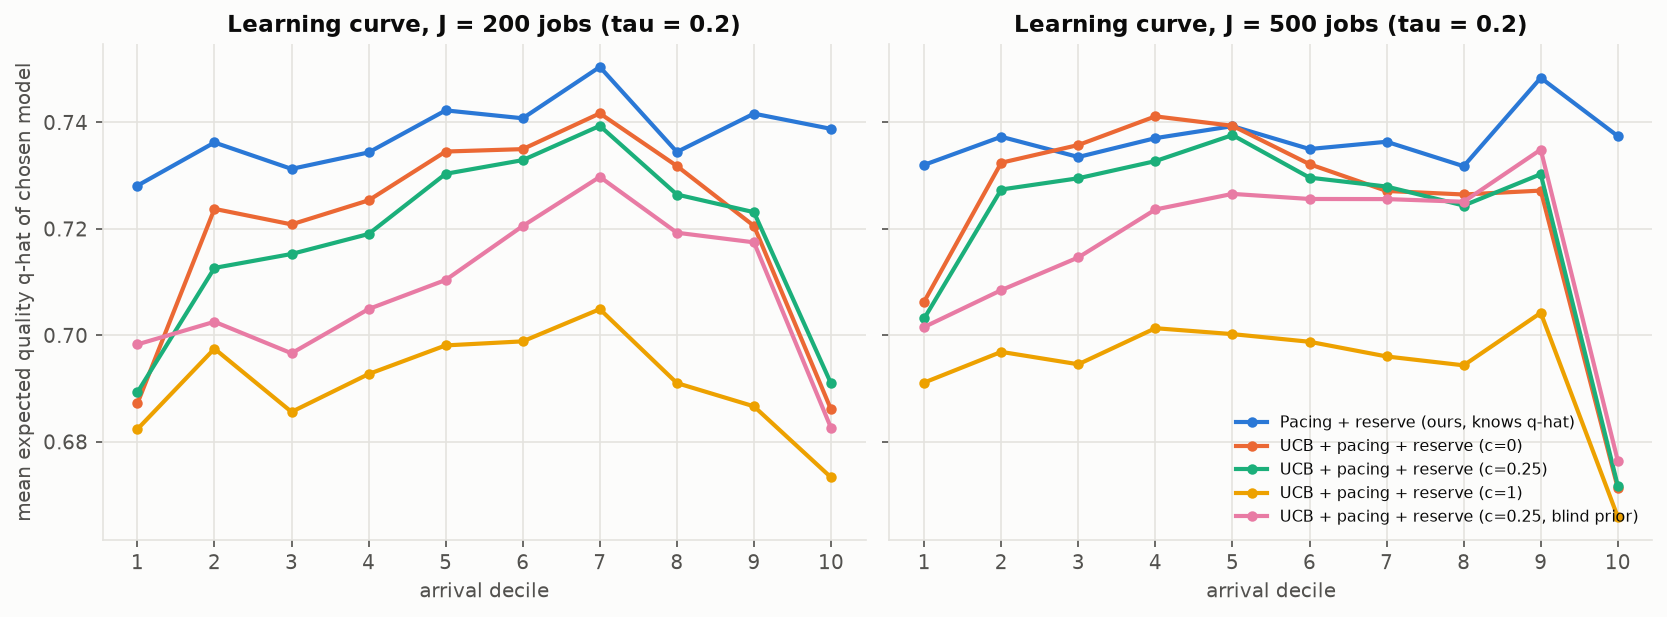

In [7]:
display(Image('experiments/figures/e08_learning.png'))